# 03 — External Data Integration & Exploratory Data Analysis (2019–2023)

This notebook documents **every feature in our dataset**, **where it comes from**, **why it is used**, and **concrete examples**, followed by an exploratory visual analysis of Germany's hourly and daily electricity grid load (`Netzlast [MWh]`).

All exploratory plots use **2019–2023 only**, keeping **2024** strictly held out for final model evaluation.

---

### Complete Feature Reference (Zero-Leakage Full-Year Feature Set)

| Feature | Granularity | Source | Why It Is Used | Concrete Example |
|---|---|---|---|---|
| `grid_load_mwh` (Target) | Hourly / Daily | SMARD (*Bundesnetzagentur*, `Realisierter Stromverbrauch — Netzlast [MWh]`) | Target electricity demand across the German transmission grid | `62,847.25 MWh` (`2024-01-15 12:00 CET`) |
| `time_years` | Hourly & Daily | Engineered from `timestamp_utc` (`(t - 2019-01-01) / 365.25`) | Captures the multi-year structural downward trend in grid load (efficiency, behind-the-meter PV, post-2022 industrial shift) | `5.038` (`2024-01-15`) |
| `hour` | Hourly | Local `Europe/Berlin` timestamp (`0–23`) | Captures Germany's strong diurnal cycle (morning industrial ramp-up, midday peak, evening household peak, night trough) | `12` (`12:00 CET`) |
| `day_of_week` | Hourly & Daily | Local calendar (`0 = Mon` .. `6 = Sun`) | Separates high-load Mon–Fri workdays from lower-load Saturdays and Sundays | `0` (Monday, `2024-01-15`) |
| `month` | Hourly & Daily | Local calendar (`1–12`) | Captures broad seasonal daylight, heating, and holiday regimes | `1` (January) |
| `day_of_year` | Hourly & Daily | Local calendar (`1–366`) | Captures smooth intra-year seasonality beyond coarse monthly boundaries | `15` (`2024-01-15`) |
| `is_weekend` | Hourly & Daily | Local calendar (`1` if Sat/Sun else `0`) | Explicit binary indicator for weekend industrial/commercial shutdown | `0` (Mon `2024-01-15`), `1` (Sat/Sun) |
| `holiday_weight` | Hourly & Daily | Python `holidays` library across all 16 German *Bundesländer*, weighted by `STATE_WEIGHTS` (`0.0–1.0`) | Quantifies the fraction of German economic/industrial load on public holiday | `0.0` (`2024-01-15`), `0.645` (*Fronleichnam* `2024-05-30`), `1.0` (*Neujahr* `2024-01-01`) |
| `is_bridge_day` | Hourly & Daily | Engineered from `holiday_weight` (`1` if Fri after Thu holiday or Mon before Tue holiday) | Captures *Brückentage*, when factories/offices take extended 4-day weekends despite not being an official holiday | `1` (`2024-05-31`, Fri after *Fronleichnam*) |
| `is_christmas_shutdown` | Hourly & Daily | Local calendar (`1` for `Dec 24 – Jan 1`, else `0`) | Captures the Germany-wide year-end industrial & commercial pause (*Betriebsferien*) | `1` (`2023-12-27`), `0` (`2024-01-15`) |
| `temp_c` / `temp_c_mean` | Hourly / Daily | Open-Meteo Historical Archive API (`temperature_2m`, 5-hub weighted composite) | Captures temperature-driven heating demand (`< 15.5°C`), lighting/appliances, and mild summer cooling (`> 22°C`) | `1.20 °C` (hourly `2024-01-15 12:00`), `-0.12 °C` (daily mean) |
| `solar_radiation_wm2` / `solar_radiation_wm2_mean` | Hourly / Daily | Open-Meteo Historical Archive API (`shortwave_radiation`, 5-hub weighted composite) | Proxies behind-the-meter rooftop PV generation (which subtracts from measured net grid load) and daylight duration | `168.45 W/m²` (hourly `2024-01-15 12:00`), `223.41 W/m²` (daily `2024-05-30`) |
| `wind_speed_kmh` / `wind_speed_kmh_mean` | Hourly / Daily | Open-Meteo Historical Archive API (`wind_speed_10m`, 5-hub weighted composite) | Captures wind-chill heat loss in winter and broader synoptic weather regimes | `21.26 km/h` (hourly `2024-01-15 12:00`), `20.23 km/h` (daily) |

---

### Why These City & Federal State Weights Were Chosen

1. **5-Hub Weather Composite Weights ([`src/weather.py`](../src/weather.py) — `GERMAN_WEATHER_HUBS`):**
   - **Essen / Ruhr (`30%`)**, **Munich (`20%`)**, **Frankfurt (`20%`)**, **Berlin (`15%`)**, **Hamburg (`15%`)**.
   - Electricity demand is concentrated in dense population metros and heavy industrial corridors rather than evenly spread across Germany's land area. Weighting these 5 hubs anchors national weather to Germany's core load centers: **Rhine-Ruhr** (largest population & heavy industry), **Bavaria/Munich**, **Rhine-Main/Frankfurt** (services, chemicals, manufacturing), **Berlin**, and **Hamburg / Northern ports**.

2. **16 Federal State Weights for `holiday_weight` ([`src/features.py`](../src/features.py) — `STATE_WEIGHTS`):**
   - Industry (~43%) and trade/services (~26%) represent ~69% of German electricity demand. Many German public holidays are **regional** (e.g., *Fronleichnam*, *Allerheiligen*, *Reformationstag*, *Heilige Drei Könige*).
   - Instead of treating a small-state holiday the same as a nationwide shutdown, `STATE_WEIGHTS` weights each *Bundesland* by its approximate share of national population and industrial electricity consumption (Destatis population & regional GDP/load shares — e.g., `NW: 21.5%`, `BY: 15.8%`, `BW: 13.4%`, `NI: 9.6%`, `HE: 7.5%`, down to `HB: 0.8%`, summing to `1.0`). Consequently, *Fronleichnam* (observed in `NW, BY, BW, HE, RP, SL`) receives `holiday_weight ≈ 0.645`, reflecting that ~64.5% of Germany's economic load is on holiday.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

REPO_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data").is_dir() and (p / "pyproject.toml").is_file()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data_loader import TARGET_COL, load_smard_daily, load_smard_hourly
from src.features import (
    DAILY_FULL_YEAR_COLS,
    HOURLY_FULL_YEAR_COLS,
    STATE_WEIGHTS,
    build_daily_features,
    build_hourly_features,
)
from src.weather import GERMAN_WEATHER_HUBS, aggregate_weather_daily, load_or_fetch_hourly_weather

sns.set_theme(style="whitegrid")

smard_h = load_smard_hourly(REPO_ROOT)
smard_d = load_smard_daily(REPO_ROOT)
wx_h = load_or_fetch_hourly_weather(REPO_ROOT)
wx_d = aggregate_weather_daily(wx_h)

hourly_df = build_hourly_features(smard_h, wx_h, target_col=TARGET_COL)
daily_df = build_daily_features(smard_d, wx_d, target_col=TARGET_COL)

processed_dir = REPO_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
hourly_df.to_csv(processed_dir / "hourly_features.csv", index=False)
daily_df.to_csv(processed_dir / "daily_features.csv", index=False)

# Strictly 2019-2023 for EDA
train_h = hourly_df.loc[hourly_df["date_local"] < "2024-01-01"].copy()
train_d = daily_df.loc[daily_df["date_local"] < "2024-01-01"].copy()

def classify_day(row):
    if row["is_christmas_shutdown"] == 1:
        return "Christmas Shutdown"
    if row["is_weekend"] == 1:
        return "Weekend"
    if row["holiday_weight"] >= 0.99:
        return "National Holiday"
    if row["holiday_weight"] > 0.05:
        return "Regional Holiday"
    if row["is_bridge_day"] == 1:
        return "Bridge Day (Brückentag)"
    return "Regular Workday"

train_d["day_category"] = train_d.apply(classify_day, axis=1)
train_h["day_category"] = train_h["date_local"].map(train_d.set_index("date_local")["day_category"])

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}
train_d["season"] = train_d["month"].map(season_map)
train_h["season"] = train_h["month"].map(season_map)

CAT_ORDER = [
    "Regular Workday",
    "Regional Holiday",
    "Bridge Day (Brückentag)",
    "Weekend",
    "Christmas Shutdown",
    "National Holiday",
]
SEASON_ORDER = ["Winter", "Spring", "Summer", "Autumn"]
DOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

print(f"Training period: {len(train_h):,} hours | {len(train_d):,} days (2019–2023)")


Training period: 43,824 hours | 1,826 days (2019–2023)


## 1. Weather Data Sourcing: Open-Meteo 5-Hub Composite

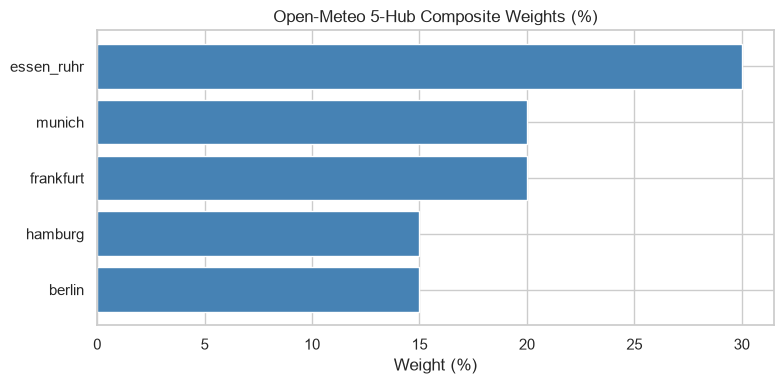

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
hub_df = pd.DataFrame(GERMAN_WEATHER_HUBS).sort_values("weight", ascending=True)
ax.barh(hub_df["name"], hub_df["weight"] * 100, color="steelblue")
ax.set_title("Open-Meteo 5-Hub Composite Weights (%)")
ax.set_xlabel("Weight (%)")
plt.tight_layout()
plt.show()

## 2. Temperature (`temp_c` / `temp_c_mean`) & Grid Load (2019–2023)

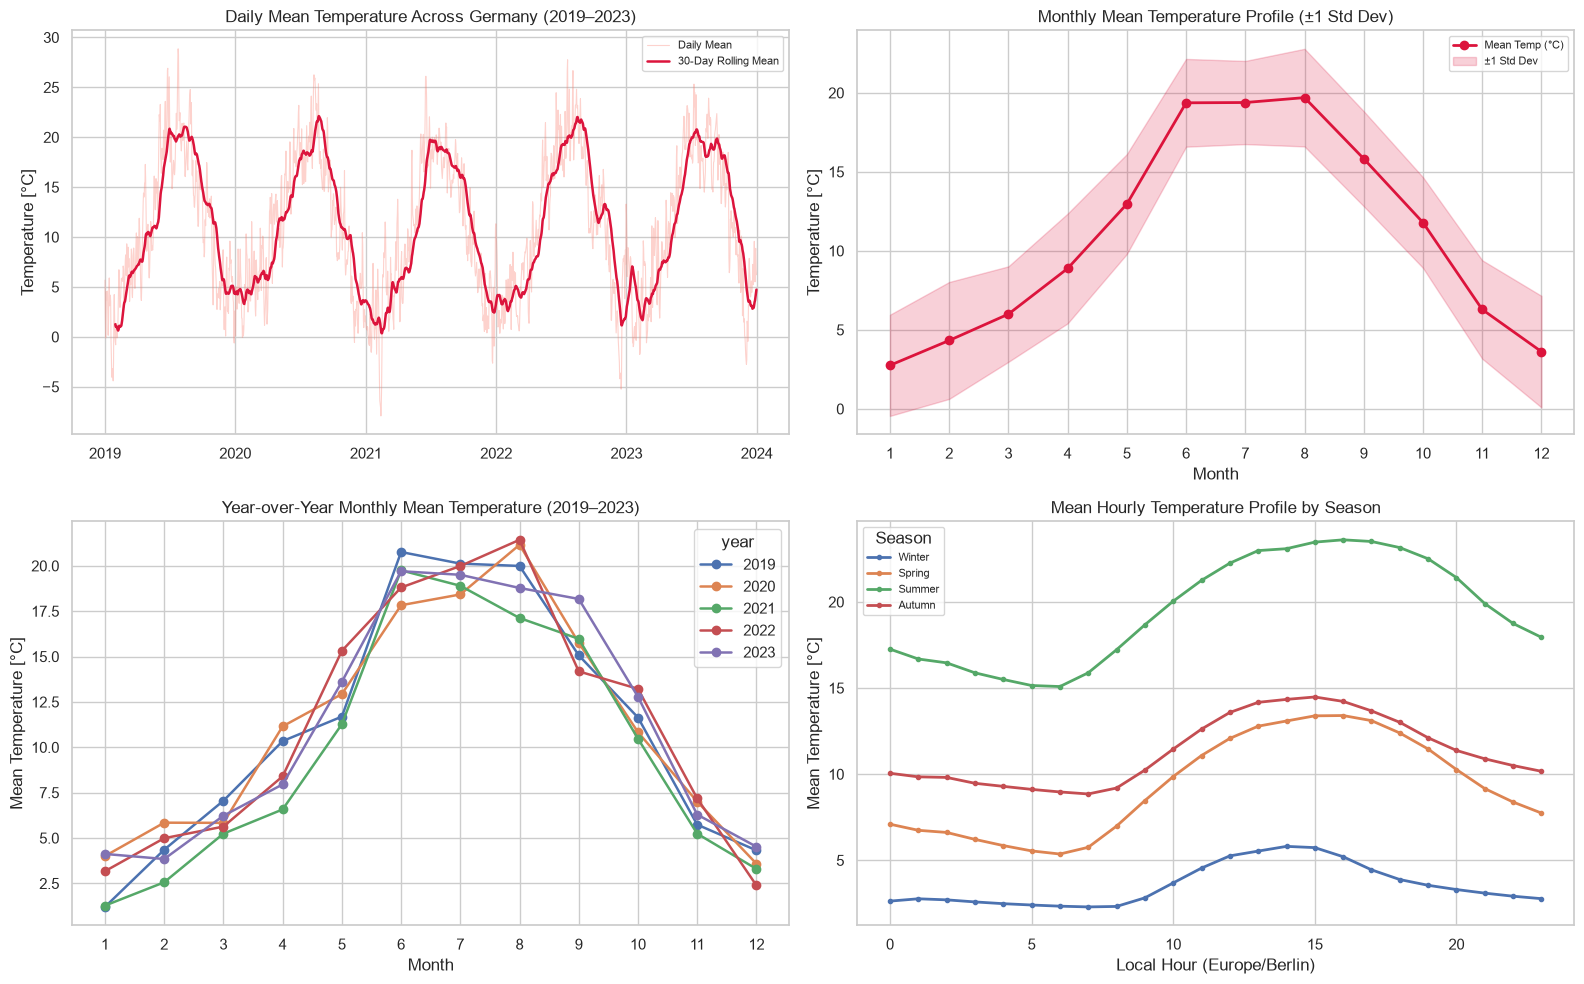

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Full timespan daily mean temperature (2019-2023)
axes[0, 0].plot(train_d["date_local"], train_d["temp_c_mean"], alpha=0.35, color="salmon", lw=0.8, label="Daily Mean")
axes[0, 0].plot(train_d["date_local"], train_d["temp_c_mean"].rolling(30).mean(), color="crimson", lw=1.8, label="30-Day Rolling Mean")
axes[0, 0].set_title("Daily Mean Temperature Across Germany (2019–2023)")
axes[0, 0].set_ylabel("Temperature [°C]")
axes[0, 0].legend(fontsize=8)

# 2. Monthly mean temperature +/- 1 std
monthly_temp = train_d.groupby("month")["temp_c_mean"].agg(["mean", "std"])
axes[0, 1].plot(monthly_temp.index, monthly_temp["mean"], marker="o", lw=2, color="crimson", label="Mean Temp (°C)")
axes[0, 1].fill_between(
    monthly_temp.index,
    monthly_temp["mean"] - monthly_temp["std"],
    monthly_temp["mean"] + monthly_temp["std"],
    alpha=0.2,
    color="crimson",
    label="±1 Std Dev",
)
axes[0, 1].set_title("Monthly Mean Temperature Profile (±1 Std Dev)")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Temperature [°C]")
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].legend(fontsize=8)

# 3. Year-over-year monthly mean temperature
train_d.pivot_table(index="month", columns="year", values="temp_c_mean", aggfunc="mean").plot(ax=axes[1, 0], marker="o", lw=1.8)
axes[1, 0].set_title("Year-over-Year Monthly Mean Temperature (2019–2023)")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Mean Temperature [°C]")
axes[1, 0].set_xticks(range(1, 13))

# 4. Hourly temperature diurnal profile by season (replaces Month x Hour heatmap)
train_h.groupby(["hour", "season"])["temp_c"].mean().unstack()[SEASON_ORDER].plot(ax=axes[1, 1], marker="o", ms=3, lw=2)
axes[1, 1].set_title("Mean Hourly Temperature Profile by Season")
axes[1, 1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1, 1].set_ylabel("Mean Temperature [°C]")
axes[1, 1].legend(title="Season", fontsize=8)

plt.tight_layout()
plt.show()

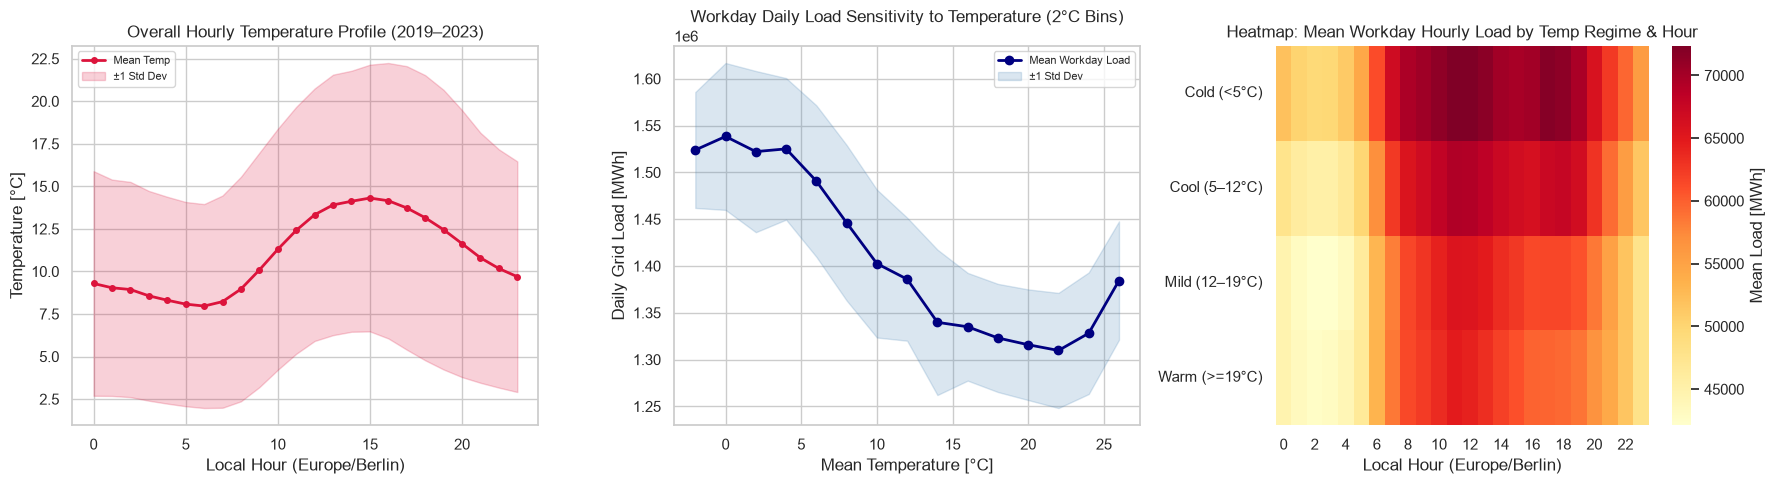

In [4]:
wd = train_d.loc[train_d["day_category"] == "Regular Workday"].copy()
wd_h = train_h.loc[train_h["day_category"] == "Regular Workday"].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Overall hourly temperature profile (mean +/- 1 std)
hourly_temp = train_h.groupby("hour")["temp_c"].agg(["mean", "std"])
axes[0].plot(hourly_temp.index, hourly_temp["mean"], marker="o", ms=4, lw=2, color="crimson", label="Mean Temp")
axes[0].fill_between(
    hourly_temp.index,
    hourly_temp["mean"] - hourly_temp["std"],
    hourly_temp["mean"] + hourly_temp["std"],
    alpha=0.2,
    color="crimson",
    label="±1 Std Dev",
)
axes[0].set_title("Overall Hourly Temperature Profile (2019–2023)")
axes[0].set_xlabel("Local Hour (Europe/Berlin)")
axes[0].set_ylabel("Temperature [°C]")
axes[0].legend(fontsize=8)

# 2. Binned Temperature Response Curve (2°C bins, Regular Workdays, no thresholds)
wd["temp_bin"] = (wd["temp_c_mean"] / 2.0).round() * 2.0
temp_curve = wd.groupby("temp_bin")[TARGET_COL].agg(["mean", "std", "count"]).query("count >= 10")
axes[1].plot(temp_curve.index, temp_curve["mean"], marker="o", color="navy", lw=2, label="Mean Workday Load")
axes[1].fill_between(
    temp_curve.index,
    temp_curve["mean"] - temp_curve["std"],
    temp_curve["mean"] + temp_curve["std"],
    alpha=0.2,
    color="steelblue",
    label="±1 Std Dev",
)
axes[1].set_title("Workday Daily Load Sensitivity to Temperature (2°C Bins)")
axes[1].set_xlabel("Mean Temperature [°C]")
axes[1].set_ylabel("Daily Grid Load [MWh]")
axes[1].legend(fontsize=8)

# 3. Hourly Load Heatmap by Temperature Regime
wd_h["temp_regime"] = pd.cut(
    wd_h["temp_c"],
    bins=[-30, 5, 12, 19, 45],
    labels=["Cold (<5°C)", "Cool (5–12°C)", "Mild (12–19°C)", "Warm (>=19°C)"],
)
hm_temp = wd_h.pivot_table(index="temp_regime", columns="hour", values=TARGET_COL, aggfunc="mean", observed=False)
assert not hm_temp.isna().any().any(), "Unexpected NaNs in temperature heatmap!"
sns.heatmap(hm_temp, cmap="YlOrRd", ax=axes[2], cbar_kws={"label": "Mean Load [MWh]"})
axes[2].set_title("Heatmap: Mean Workday Hourly Load by Temp Regime & Hour")
axes[2].set_xlabel("Local Hour (Europe/Berlin)")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

## 3. Solar Radiation (`solar_radiation_wm2` / `solar_radiation_wm2_mean`) & Grid Load (2019–2023)

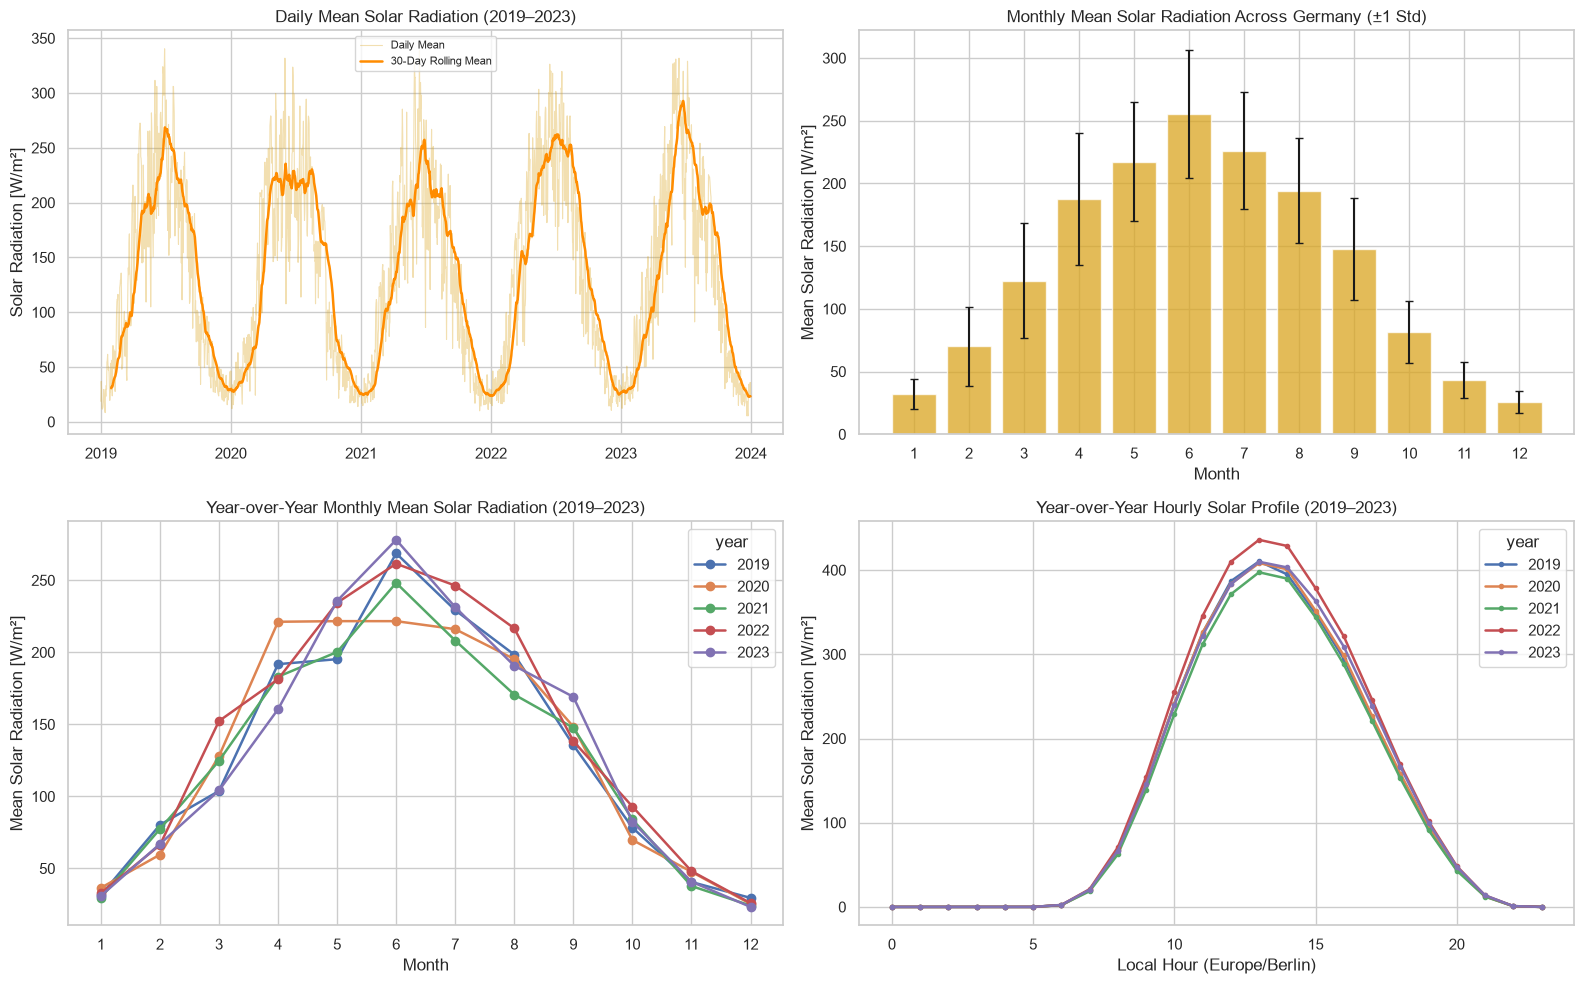

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Full timespan daily mean solar radiation (2019-2023)
axes[0, 0].plot(train_d["date_local"], train_d["solar_radiation_wm2_mean"], alpha=0.35, color="goldenrod", lw=0.8, label="Daily Mean")
axes[0, 0].plot(train_d["date_local"], train_d["solar_radiation_wm2_mean"].rolling(30).mean(), color="darkorange", lw=1.8, label="30-Day Rolling Mean")
axes[0, 0].set_title("Daily Mean Solar Radiation (2019–2023)")
axes[0, 0].set_ylabel("Solar Radiation [W/m²]")
axes[0, 0].legend(fontsize=8)

# 2. Monthly mean solar radiation +/- 1 std
monthly_solar = train_d.groupby("month")["solar_radiation_wm2_mean"].agg(["mean", "std"])
axes[0, 1].bar(monthly_solar.index, monthly_solar["mean"], yerr=monthly_solar["std"], capsize=3, alpha=0.75, color="goldenrod")
axes[0, 1].set_title("Monthly Mean Solar Radiation Across Germany (±1 Std)")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Mean Solar Radiation [W/m²]")
axes[0, 1].set_xticks(range(1, 13))

# 3. Year-over-year monthly mean solar radiation
train_d.pivot_table(index="month", columns="year", values="solar_radiation_wm2_mean", aggfunc="mean").plot(ax=axes[1, 0], marker="o", lw=1.8)
axes[1, 0].set_title("Year-over-Year Monthly Mean Solar Radiation (2019–2023)")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Mean Solar Radiation [W/m²]")
axes[1, 0].set_xticks(range(1, 13))

# 4. Year-over-year hourly solar profile
train_h.pivot_table(index="hour", columns="year", values="solar_radiation_wm2", aggfunc="mean").plot(ax=axes[1, 1], marker="o", ms=3, lw=1.8)
axes[1, 1].set_title("Year-over-Year Hourly Solar Profile (2019–2023)")
axes[1, 1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1, 1].set_ylabel("Mean Solar Radiation [W/m²]")

plt.tight_layout()
plt.show()

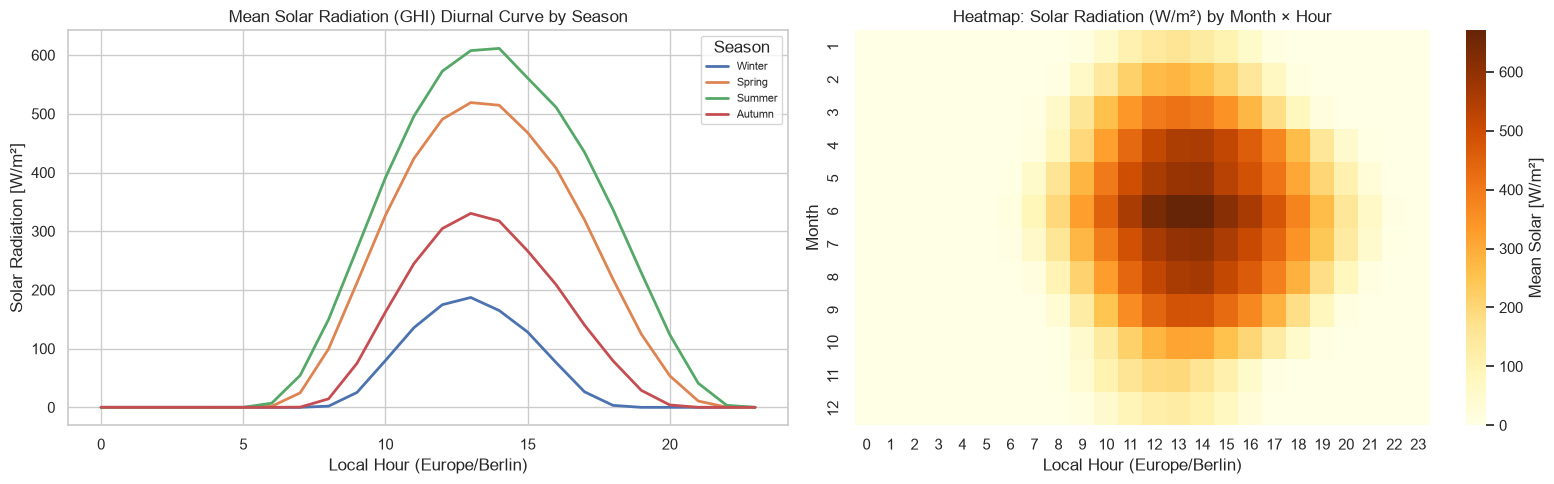

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Solar Radiation Diurnal Curve by Season
train_h.groupby(["hour", "season"])["solar_radiation_wm2"].mean().unstack()[SEASON_ORDER].plot(ax=axes[0], lw=2)
axes[0].set_title("Mean Solar Radiation (GHI) Diurnal Curve by Season")
axes[0].set_xlabel("Local Hour (Europe/Berlin)")
axes[0].set_ylabel("Solar Radiation [W/m²]")
axes[0].legend(title="Season", fontsize=8)

# 2. Heatmap: Solar Radiation by Month x Hour
hm_wx_s = train_h.pivot_table(index="month", columns="hour", values="solar_radiation_wm2", aggfunc="mean")
assert not hm_wx_s.isna().any().any()
sns.heatmap(hm_wx_s, cmap="YlOrBr", ax=axes[1], cbar_kws={"label": "Mean Solar [W/m²]"})
axes[1].set_title("Heatmap: Solar Radiation (W/m²) by Month × Hour")
axes[1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1].set_ylabel("Month")

plt.tight_layout()
plt.show()

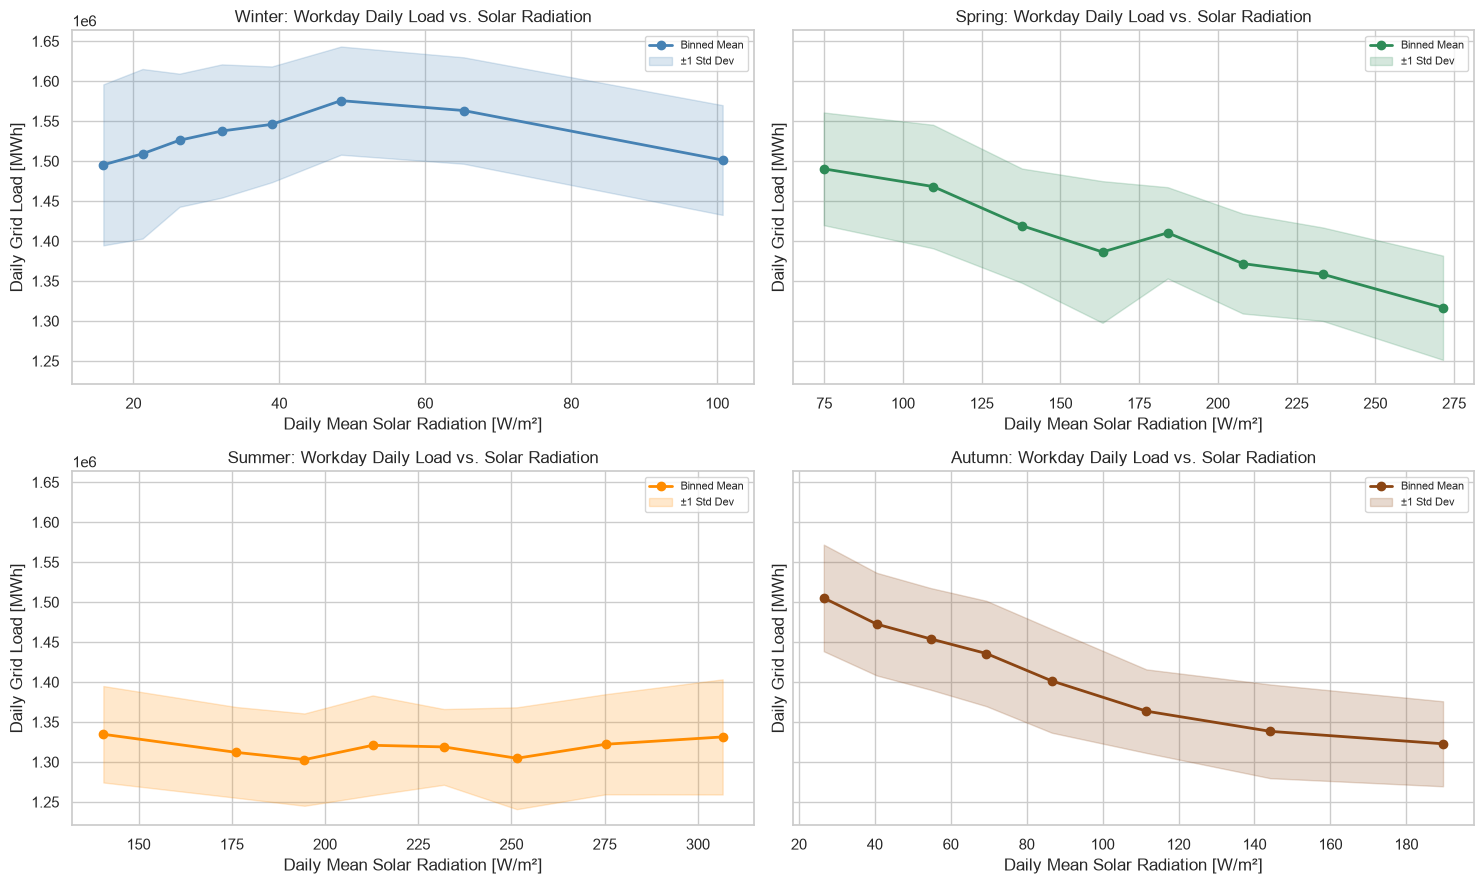

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharey=True)
season_colors = {"Winter": "steelblue", "Spring": "seagreen", "Summer": "darkorange", "Autumn": "saddlebrown"}

for ax, season in zip(axes.flat, SEASON_ORDER):
    sub = wd.loc[wd["season"] == season].copy()
    sub["solar_bin"] = pd.qcut(sub["solar_radiation_wm2_mean"], q=8, duplicates="drop")
    curve = sub.groupby("solar_bin", observed=False).agg(
        x=("solar_radiation_wm2_mean", "mean"),
        mean=(TARGET_COL, "mean"),
        std=(TARGET_COL, "std"),
    )
    ax.plot(curve["x"], curve["mean"], marker="o", lw=2, color=season_colors[season], label="Binned Mean")
    ax.fill_between(curve["x"], curve["mean"] - curve["std"], curve["mean"] + curve["std"], alpha=0.2, color=season_colors[season], label="±1 Std Dev")
    ax.set_title(f"{season}: Workday Daily Load vs. Solar Radiation")
    ax.set_xlabel("Daily Mean Solar Radiation [W/m²]")
    ax.set_ylabel("Daily Grid Load [MWh]")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

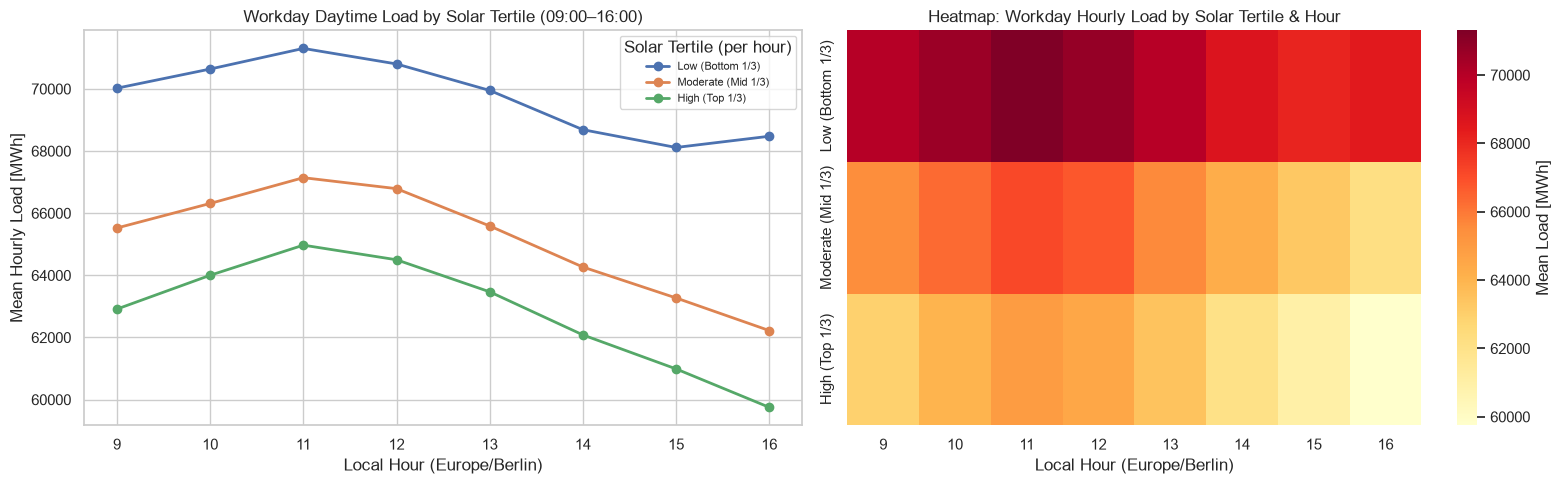

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

day_h = wd_h.loc[wd_h["hour"].between(9, 16)].copy()
day_h["solar_regime"] = (
    day_h.groupby("hour")["solar_radiation_wm2"]
    .transform(lambda s: pd.qcut(s, q=3, labels=["Low (Bottom 1/3)", "Moderate (Mid 1/3)", "High (Top 1/3)"]))
)
solar_order = ["Low (Bottom 1/3)", "Moderate (Mid 1/3)", "High (Top 1/3)"]

day_h.groupby(["hour", "solar_regime"], observed=False)[TARGET_COL].mean().unstack()[solar_order].plot(ax=axes[0], marker="o", lw=2)
axes[0].set_title("Workday Daytime Load by Solar Tertile (09:00–16:00)")
axes[0].set_xlabel("Local Hour (Europe/Berlin)")
axes[0].set_ylabel("Mean Hourly Load [MWh]")
axes[0].legend(title="Solar Tertile (per hour)", fontsize=8)

hm_solar_load = day_h.pivot_table(index="solar_regime", columns="hour", values=TARGET_COL, aggfunc="mean", observed=False).reindex(solar_order)
assert not hm_solar_load.isna().any().any(), "Unexpected NaNs in solar load heatmap!"
sns.heatmap(hm_solar_load, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Mean Load [MWh]"})
axes[1].set_title("Heatmap: Workday Hourly Load by Solar Tertile & Hour")
axes[1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 4. Wind Speed (`wind_speed_kmh` / `wind_speed_kmh_mean`) & Grid Load (2019–2023)

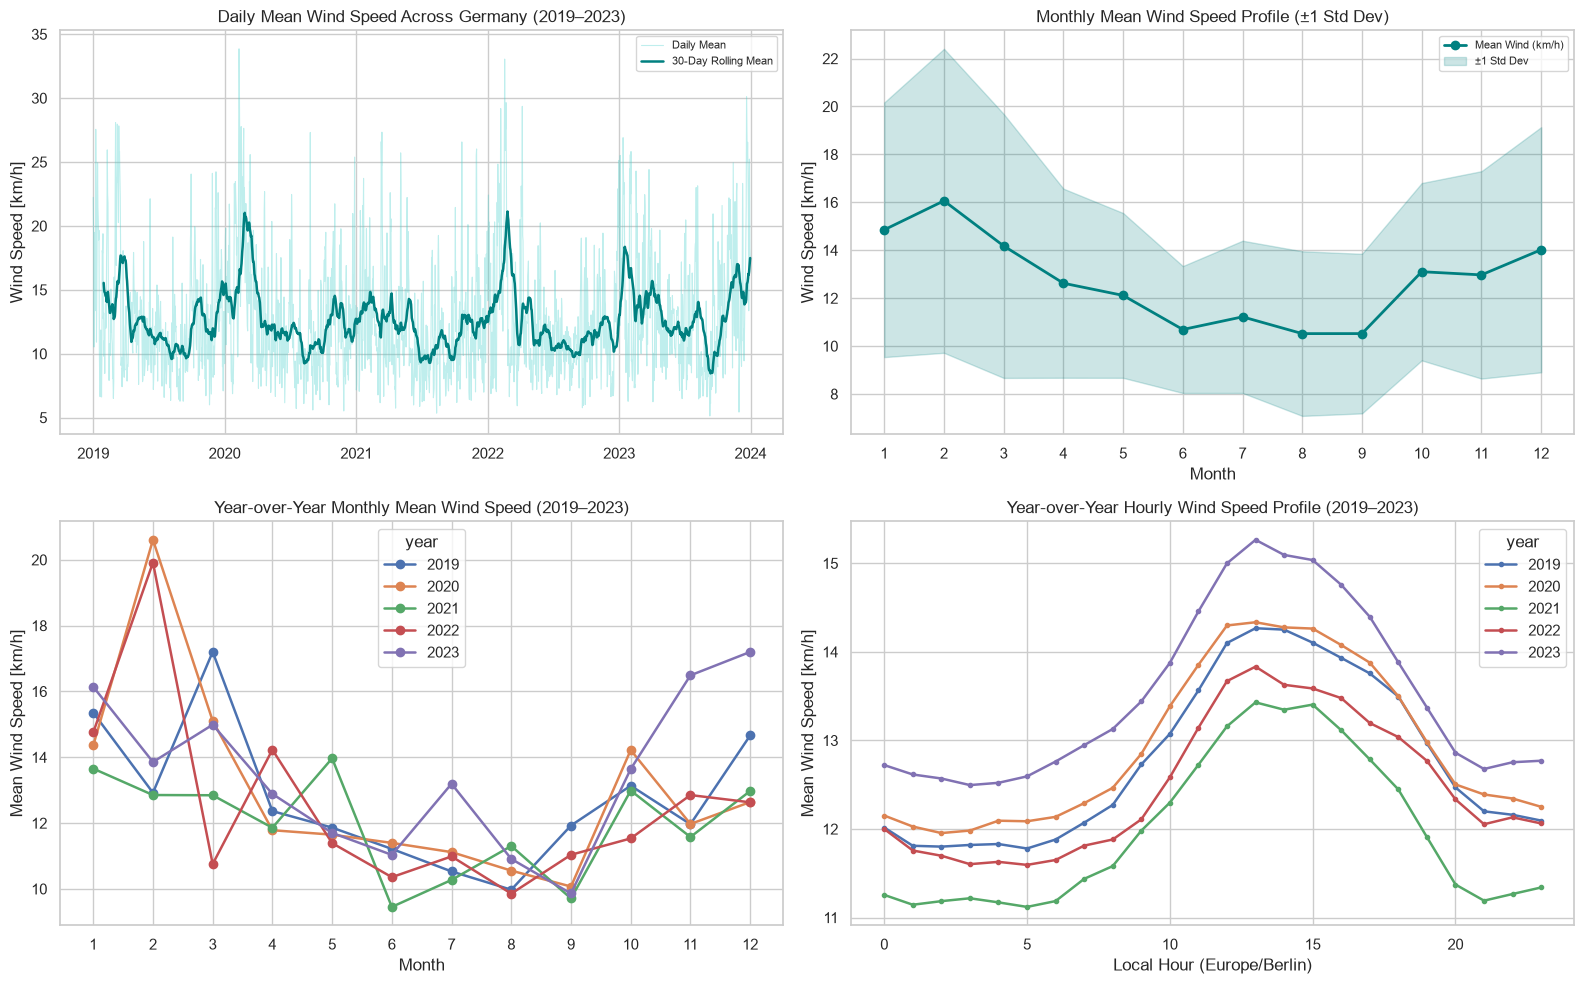

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Full timespan daily mean wind speed (2019-2023)
axes[0, 0].plot(train_d["date_local"], train_d["wind_speed_kmh_mean"], alpha=0.35, color="mediumturquoise", lw=0.8, label="Daily Mean")
axes[0, 0].plot(train_d["date_local"], train_d["wind_speed_kmh_mean"].rolling(30).mean(), color="teal", lw=1.8, label="30-Day Rolling Mean")
axes[0, 0].set_title("Daily Mean Wind Speed Across Germany (2019–2023)")
axes[0, 0].set_ylabel("Wind Speed [km/h]")
axes[0, 0].legend(fontsize=8)

# 2. Monthly mean wind speed +/- 1 std
monthly_wind = train_d.groupby("month")["wind_speed_kmh_mean"].agg(["mean", "std"])
axes[0, 1].plot(monthly_wind.index, monthly_wind["mean"], marker="o", lw=2, color="teal", label="Mean Wind (km/h)")
axes[0, 1].fill_between(
    monthly_wind.index,
    monthly_wind["mean"] - monthly_wind["std"],
    monthly_wind["mean"] + monthly_wind["std"],
    alpha=0.2,
    color="teal",
    label="±1 Std Dev",
)
axes[0, 1].set_title("Monthly Mean Wind Speed Profile (±1 Std Dev)")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Wind Speed [km/h]")
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].legend(fontsize=8)

# 3. Year-over-year monthly mean wind speed
train_d.pivot_table(index="month", columns="year", values="wind_speed_kmh_mean", aggfunc="mean").plot(ax=axes[1, 0], marker="o", lw=1.8)
axes[1, 0].set_title("Year-over-Year Monthly Mean Wind Speed (2019–2023)")
axes[1, 0].set_xlabel("Month")
axes[1, 0].set_ylabel("Mean Wind Speed [km/h]")
axes[1, 0].set_xticks(range(1, 13))

# 4. Year-over-year hourly wind profile
train_h.pivot_table(index="hour", columns="year", values="wind_speed_kmh", aggfunc="mean").plot(ax=axes[1, 1], marker="o", ms=3, lw=1.8)
axes[1, 1].set_title("Year-over-Year Hourly Wind Speed Profile (2019–2023)")
axes[1, 1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1, 1].set_ylabel("Mean Wind Speed [km/h]")

plt.tight_layout()
plt.show()

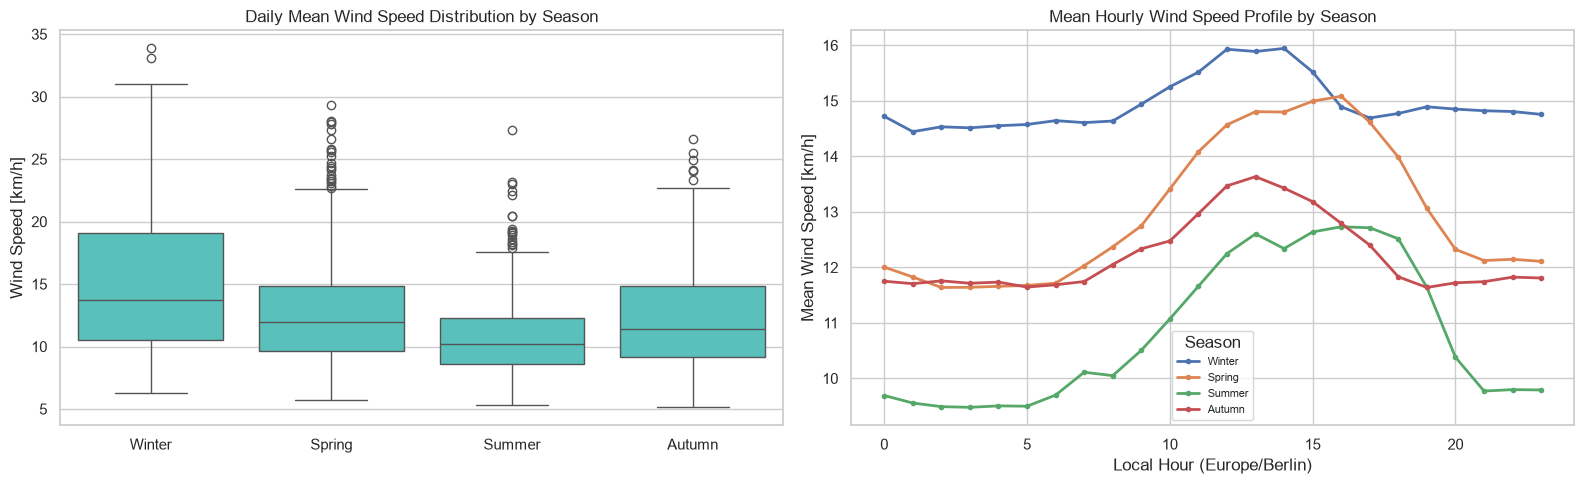

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(data=train_d, x="season", y="wind_speed_kmh_mean", order=SEASON_ORDER, color="mediumturquoise", ax=axes[0])
axes[0].set_title("Daily Mean Wind Speed Distribution by Season")
axes[0].set_xlabel("")
axes[0].set_ylabel("Wind Speed [km/h]")

train_h.groupby(["hour", "season"])["wind_speed_kmh"].mean().unstack()[SEASON_ORDER].plot(ax=axes[1], marker="o", ms=3, lw=2)
axes[1].set_title("Mean Hourly Wind Speed Profile by Season")
axes[1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1].set_ylabel("Mean Wind Speed [km/h]")
axes[1].legend(title="Season", fontsize=8)

plt.tight_layout()
plt.show()

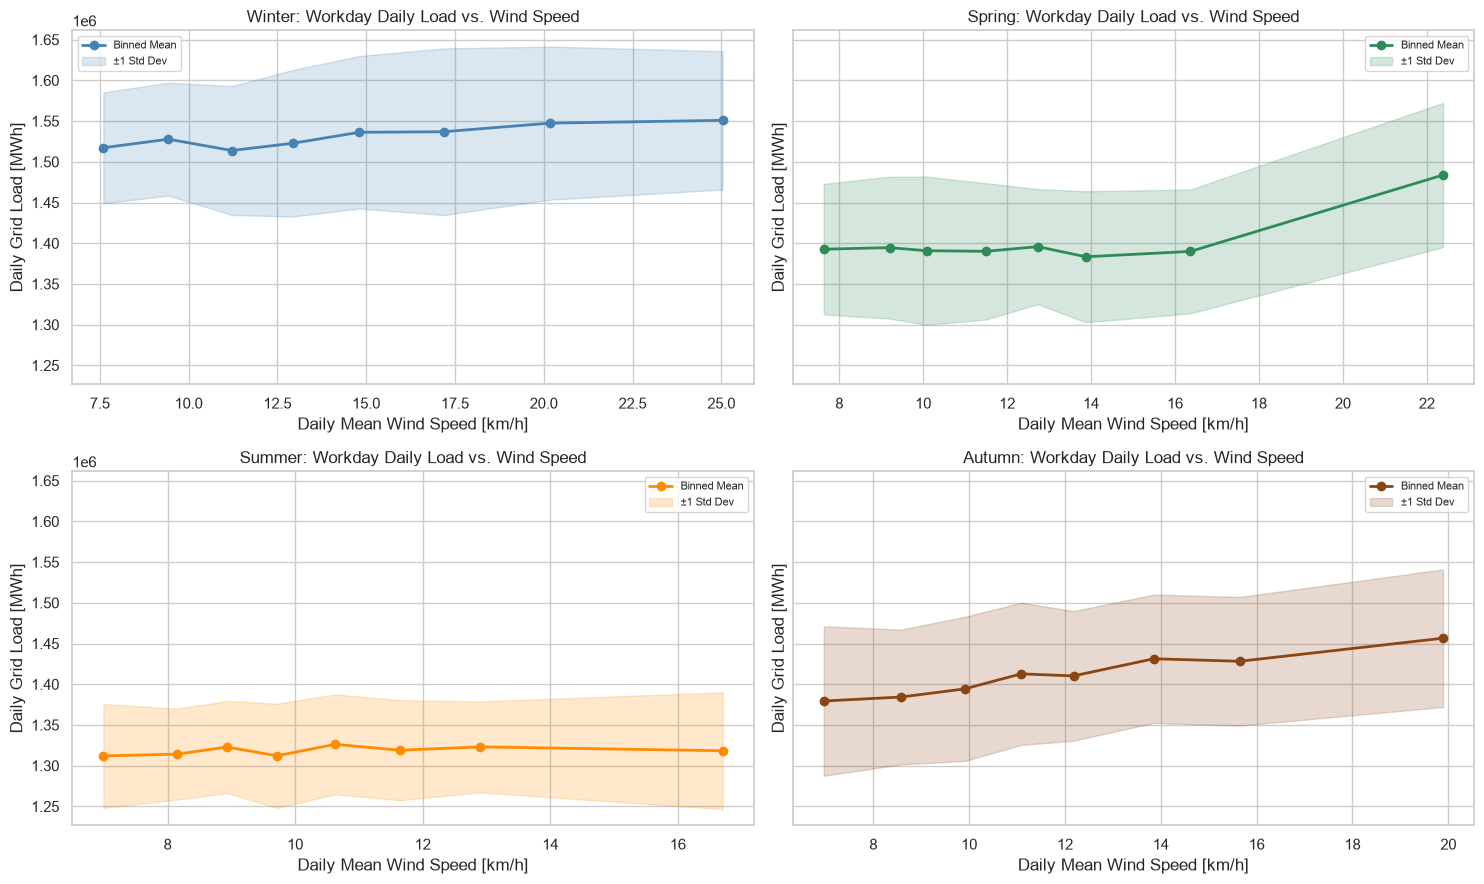

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharey=True)

for ax, season in zip(axes.flat, SEASON_ORDER):
    sub = wd.loc[wd["season"] == season].copy()
    sub["wind_bin"] = pd.qcut(sub["wind_speed_kmh_mean"], q=8, duplicates="drop")
    curve = sub.groupby("wind_bin", observed=False).agg(
        x=("wind_speed_kmh_mean", "mean"),
        mean=(TARGET_COL, "mean"),
        std=(TARGET_COL, "std"),
    )
    ax.plot(curve["x"], curve["mean"], marker="o", lw=2, color=season_colors[season], label="Binned Mean")
    ax.fill_between(curve["x"], curve["mean"] - curve["std"], curve["mean"] + curve["std"], alpha=0.2, color=season_colors[season], label="±1 Std Dev")
    ax.set_title(f"{season}: Workday Daily Load vs. Wind Speed")
    ax.set_xlabel("Daily Mean Wind Speed [km/h]")
    ax.set_ylabel("Daily Grid Load [MWh]")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

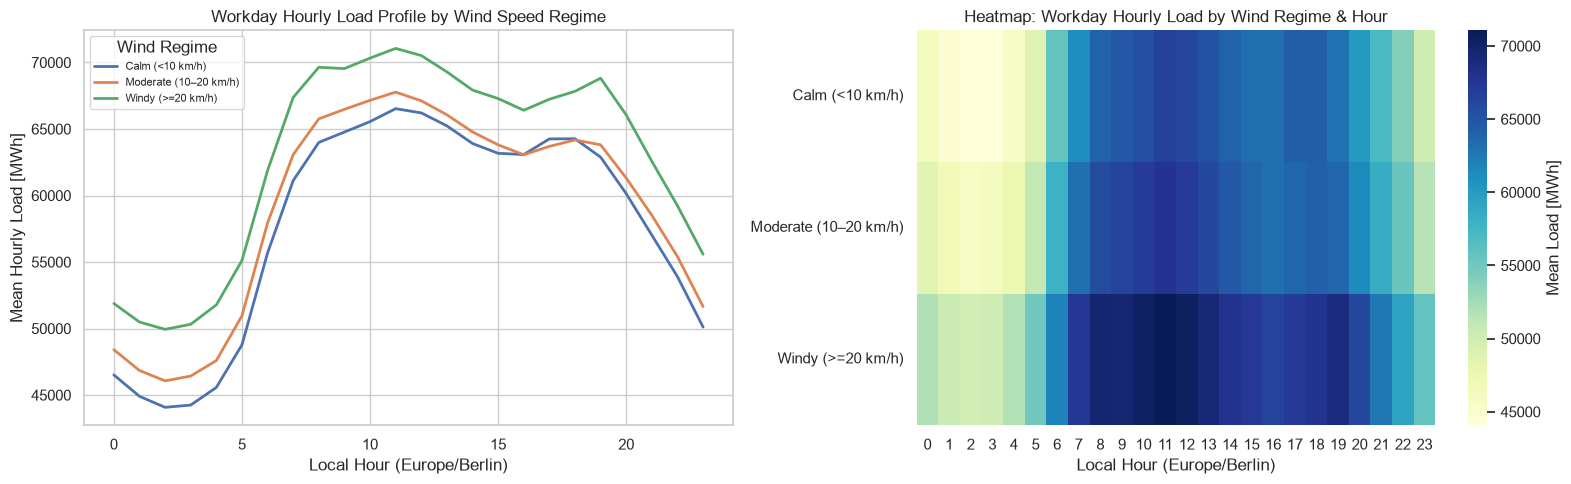

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

wd_h["wind_regime"] = pd.cut(
    wd_h["wind_speed_kmh"],
    bins=[-1, 10, 20, 120],
    labels=["Calm (<10 km/h)", "Moderate (10–20 km/h)", "Windy (>=20 km/h)"],
)
wd_h.groupby(["hour", "wind_regime"], observed=False)[TARGET_COL].mean().unstack().plot(ax=axes[0], lw=2)
axes[0].set_title("Workday Hourly Load Profile by Wind Speed Regime")
axes[0].set_xlabel("Local Hour (Europe/Berlin)")
axes[0].set_ylabel("Mean Hourly Load [MWh]")
axes[0].legend(title="Wind Regime", fontsize=8)

hm_wind_load = wd_h.pivot_table(index="wind_regime", columns="hour", values=TARGET_COL, aggfunc="mean", observed=False)
assert not hm_wind_load.isna().any().any(), "Unexpected NaNs in wind load heatmap!"
sns.heatmap(hm_wind_load, cmap="YlGnBu", ax=axes[1], cbar_kws={"label": "Mean Load [MWh]"})
axes[1].set_title("Heatmap: Workday Hourly Load by Wind Regime & Hour")
axes[1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 5. German Holidays, `holiday_weight`, Bridge Days & Calendar Categories (2019–2023)

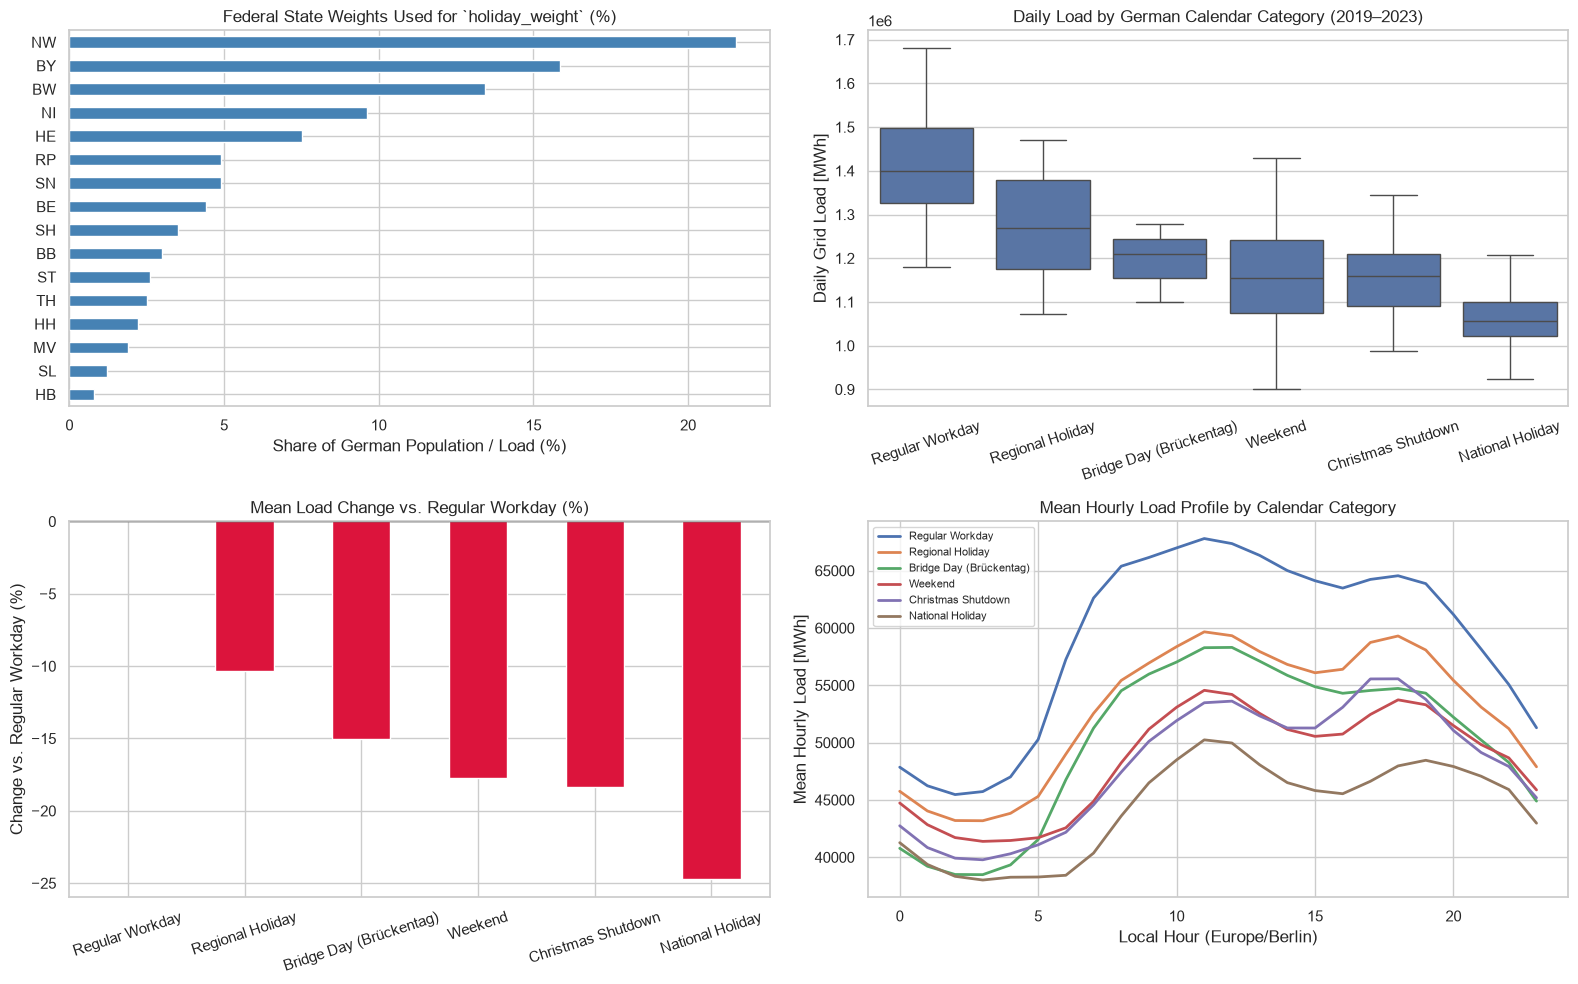

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Federal state weights used in holiday_weight
sw = pd.Series(STATE_WEIGHTS).sort_values(ascending=True) * 100
sw.plot(kind="barh", color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Federal State Weights Used for `holiday_weight` (%)")
axes[0, 0].set_xlabel("Share of German Population / Load (%)")

# 2. Daily load boxplot by German calendar category (sorted per requested order)
sns.boxplot(data=train_d, x="day_category", y=TARGET_COL, order=CAT_ORDER, ax=axes[0, 1])
axes[0, 1].set_title("Daily Load by German Calendar Category (2019–2023)")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Daily Grid Load [MWh]")
axes[0, 1].tick_params(axis="x", rotation=18)

# 3. Percentage load drop relative to Regular Workday (sorted per requested order)
cat_means = train_d.groupby("day_category")[TARGET_COL].mean().reindex(CAT_ORDER)
pct_diff = ((cat_means / cat_means["Regular Workday"]) - 1.0) * 100.0
colors = ["steelblue" if v >= 0 else "crimson" for v in pct_diff]
pct_diff.plot(kind="bar", color=colors, ax=axes[1, 0])
axes[1, 0].axhline(0, color="black", lw=1)
axes[1, 0].set_title("Mean Load Change vs. Regular Workday (%)")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Change vs. Regular Workday (%)")
axes[1, 0].tick_params(axis="x", rotation=18)

# 4. Hourly Diurnal Curves by German Calendar Category
cat_diurnal = train_h.pivot_table(index="hour", columns="day_category", values=TARGET_COL, aggfunc="mean")[CAT_ORDER]
cat_diurnal.plot(ax=axes[1, 1], lw=2)
axes[1, 1].set_title("Mean Hourly Load Profile by Calendar Category")
axes[1, 1].set_xlabel("Local Hour (Europe/Berlin)")
axes[1, 1].set_ylabel("Mean Hourly Load [MWh]")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()


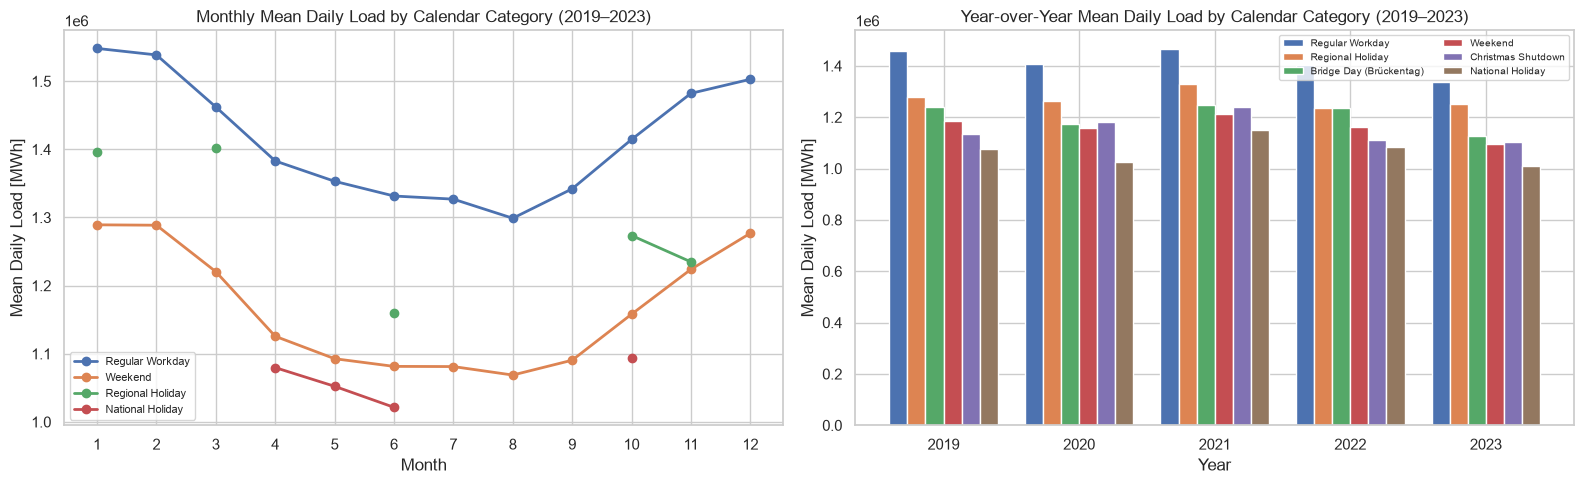

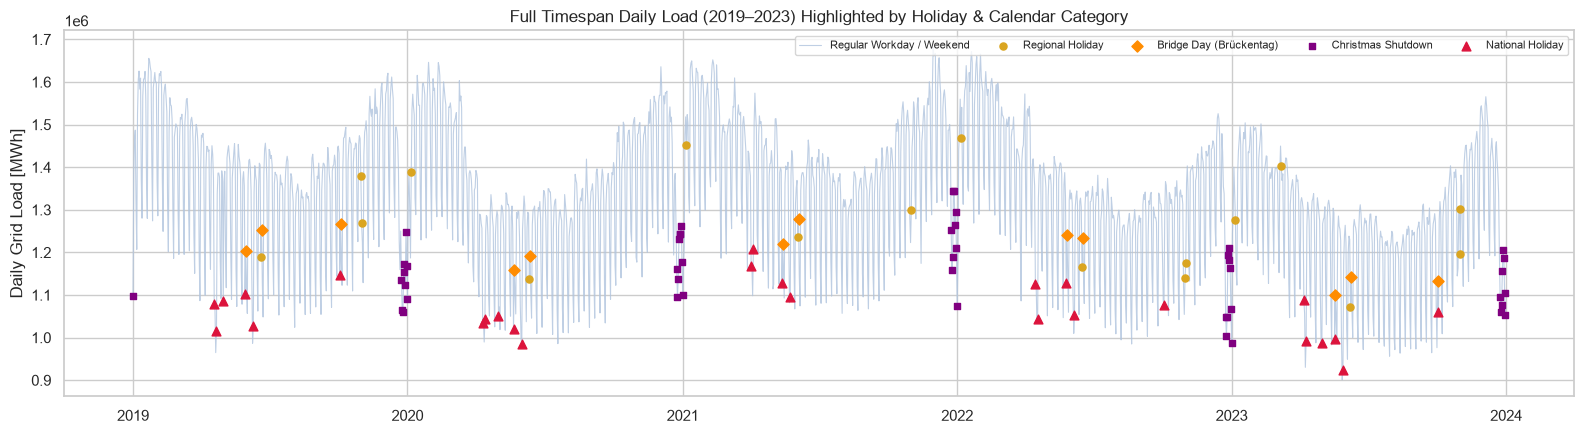

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Monthly Mean Daily Load by Calendar Category (main categories)
main_cats = ["Regular Workday", "Weekend", "Regional Holiday", "National Holiday"]
train_d.loc[train_d["day_category"].isin(main_cats)].pivot_table(
    index="month", columns="day_category", values=TARGET_COL, aggfunc="mean"
)[main_cats].plot(ax=axes[0], marker="o", lw=2)
axes[0].set_title("Monthly Mean Daily Load by Calendar Category (2019–2023)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Mean Daily Load [MWh]")
axes[0].set_xticks(range(1, 13))
axes[0].legend(title="", fontsize=8)

# 2. Year-over-Year Mean Daily Load by Calendar Category
train_d.pivot_table(
    index="year", columns="day_category", values=TARGET_COL, aggfunc="mean"
)[CAT_ORDER].plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set_title("Year-over-Year Mean Daily Load by Calendar Category (2019–2023)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Mean Daily Load [MWh]")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="", fontsize=7, ncol=2)

plt.tight_layout()
plt.show()

# 3. Full Timespan Daily Load (2019–2023) Highlighted by Calendar Category
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(train_d["date_local"], train_d[TARGET_COL], color="lightsteelblue", lw=0.8, alpha=0.8, label="Regular Workday / Weekend")
cat_styles = {
    "Regional Holiday": ("goldenrod", "o", 26),
    "Bridge Day (Brückentag)": ("darkorange", "D", 32),
    "Christmas Shutdown": ("purple", "s", 24),
    "National Holiday": ("crimson", "^", 40),
}
for cat, (col, mkr, sz) in cat_styles.items():
    sub = train_d.loc[train_d["day_category"] == cat]
    ax.scatter(sub["date_local"], sub[TARGET_COL], color=col, marker=mkr, s=sz, zorder=4, label=cat)
ax.set_title("Full Timespan Daily Load (2019–2023) Highlighted by Holiday & Calendar Category")
ax.set_ylabel("Daily Grid Load [MWh]")
ax.legend(ncol=5, fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

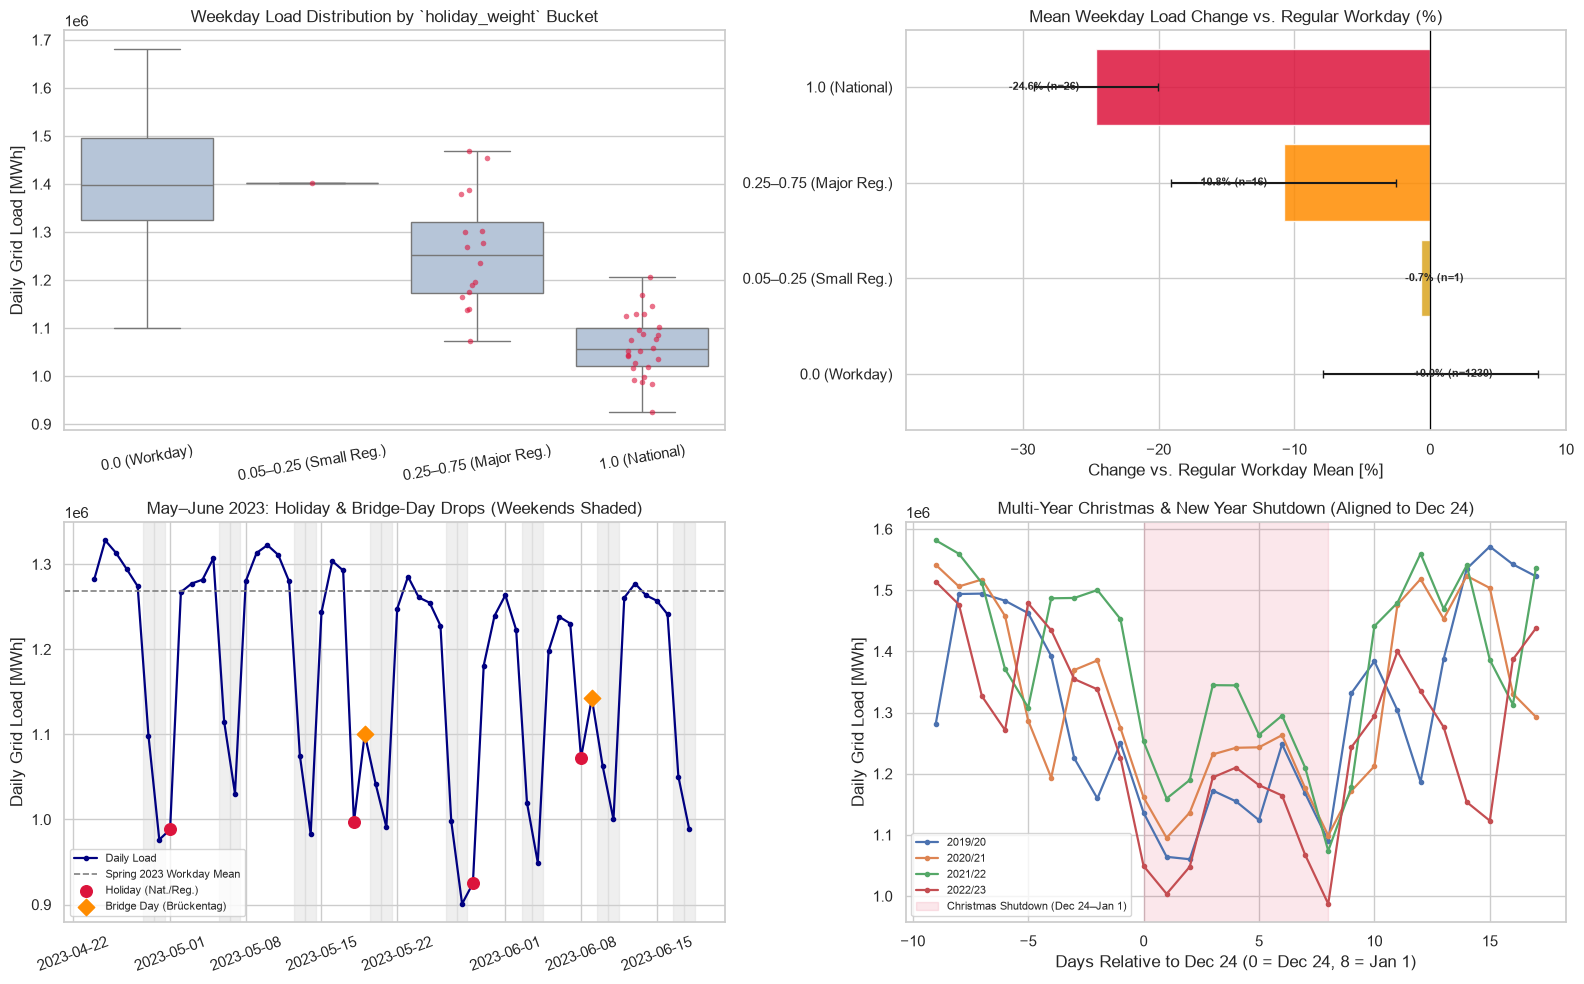

In [15]:
wkdays = train_d.loc[(train_d["is_weekend"] == 0) & (train_d["is_christmas_shutdown"] == 0)].copy()
wkdays["hw_bucket"] = pd.cut(
    wkdays["holiday_weight"],
    bins=[-0.01, 0.05, 0.25, 0.75, 1.01],
    labels=["0.0 (Workday)", "0.05–0.25 (Small Reg.)", "0.25–0.75 (Major Reg.)", "1.0 (National)"],
)
bucket_order = ["0.0 (Workday)", "0.05–0.25 (Small Reg.)", "0.25–0.75 (Major Reg.)", "1.0 (National)"]
reg_mean = wkdays.loc[wkdays["hw_bucket"] == "0.0 (Workday)", TARGET_COL].mean()

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Distribution by holiday_weight group (boxplot + jittered points)
sns.boxplot(data=wkdays, x="hw_bucket", y=TARGET_COL, order=bucket_order, color="lightsteelblue", showfliers=False, ax=axes[0, 0])
sns.stripplot(data=wkdays.loc[wkdays["holiday_weight"] > 0.05], x="hw_bucket", y=TARGET_COL, order=bucket_order, color="crimson", alpha=0.6, size=4, ax=axes[0, 0])
axes[0, 0].set_title("Weekday Load Distribution by `holiday_weight` Bucket")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Daily Grid Load [MWh]")
axes[0, 0].tick_params(axis="x", rotation=10)

# 2. Relative % Load Drop vs Regular Workday (horizontal bar + std + n)
b_stats = wkdays.groupby("hw_bucket", observed=False)[TARGET_COL].agg(["mean", "std", "count"]).reindex(bucket_order)
b_stats["pct_diff"] = (b_stats["mean"] / reg_mean - 1.0) * 100
b_stats["pct_std"] = (b_stats["std"] / reg_mean) * 100
colors_b = ["steelblue", "goldenrod", "darkorange", "crimson"]
bars = axes[0, 1].barh(b_stats.index.astype(str), b_stats["pct_diff"], xerr=b_stats["pct_std"], color=colors_b, alpha=0.85, capsize=3)
axes[0, 1].axvline(0, color="black", lw=0.9)
for bar, (_, row) in zip(bars, b_stats.iterrows()):
    axes[0, 1].text(row["pct_diff"] - 1.2, bar.get_y() + bar.get_height() / 2, f"{row['pct_diff']:+.1f}% (n={int(row['count'])})", va="center", ha="right" if row["pct_diff"] < -5 else "left", fontsize=8, fontweight="bold")
axes[0, 1].set_xlim(b_stats["pct_diff"].min() - 14, 10)
axes[0, 1].set_title("Mean Weekday Load Change vs. Regular Workday (%)")
axes[0, 1].set_xlabel("Change vs. Regular Workday Mean [%]")

# 3. May-June 2023 with Weekends Shaded & Workday Baseline
spring23 = train_d.loc[(train_d["date_local"] >= "2023-04-24") & (train_d["date_local"] <= "2023-06-18")].copy()
axes[1, 0].plot(spring23["date_local"], spring23[TARGET_COL], color="navy", lw=1.6, marker="o", ms=3, label="Daily Load")
axes[1, 0].axhline(spring23.loc[spring23["day_category"] == "Regular Workday", TARGET_COL].mean(), color="gray", ls="--", lw=1.2, label="Spring 2023 Workday Mean")
for dt in spring23.loc[spring23["is_weekend"] == 1, "date_local"]:
    axes[1, 0].axvspan(dt - pd.Timedelta(hours=12), dt + pd.Timedelta(hours=12), color="lightgray", alpha=0.35)
hol_pts = spring23.loc[spring23["holiday_weight"] > 0.05]
br_pts = spring23.loc[spring23["is_bridge_day"] == 1]
axes[1, 0].scatter(hol_pts["date_local"], hol_pts[TARGET_COL], color="crimson", s=70, zorder=5, label="Holiday (Nat./Reg.)")
axes[1, 0].scatter(br_pts["date_local"], br_pts[TARGET_COL], color="darkorange", s=70, marker="D", zorder=5, label="Bridge Day (Brückentag)")
axes[1, 0].set_title("May–June 2023: Holiday & Bridge-Day Drops (Weekends Shaded)")
axes[1, 0].set_ylabel("Daily Grid Load [MWh]")
axes[1, 0].tick_params(axis="x", rotation=20)
axes[1, 0].legend(fontsize=8)

# 4. Multi-year aligned Christmas Shutdown (Dec 15 - Jan 10 across 4 winters)
for start_yr in [2019, 2020, 2021, 2022]:
    win = train_d.loc[
        (train_d["date_local"] >= f"{start_yr}-12-15") & (train_d["date_local"] <= f"{start_yr + 1}-01-10")
    ].copy()
    win["day_offset"] = (win["date_local"] - pd.Timestamp(f"{start_yr}-12-24")).dt.days
    axes[1, 1].plot(win["day_offset"], win[TARGET_COL], marker="o", ms=3, lw=1.6, label=f"{start_yr}/{str(start_yr + 1)[-2:]}")
axes[1, 1].axvspan(0, 8, color="crimson", alpha=0.10, label="Christmas Shutdown (Dec 24–Jan 1)")
axes[1, 1].set_title("Multi-Year Christmas & New Year Shutdown (Aligned to Dec 24)")
axes[1, 1].set_xlabel("Days Relative to Dec 24 (0 = Dec 24, 8 = Jan 1)")
axes[1, 1].set_ylabel("Daily Grid Load [MWh]")
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.show()

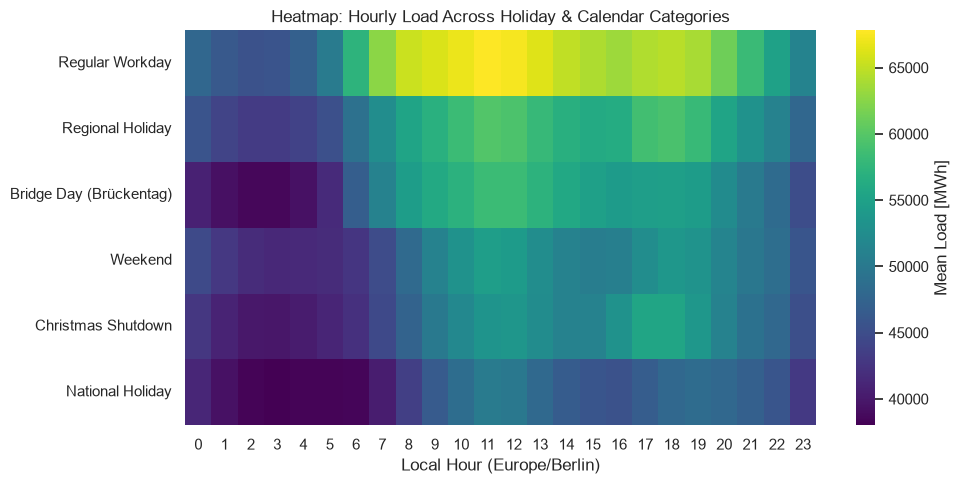

In [16]:
hm_cat = train_h.pivot_table(index="day_category", columns="hour", values=TARGET_COL, aggfunc="mean").reindex(CAT_ORDER)
assert not hm_cat.isna().any().any()

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(hm_cat, cmap="viridis", ax=ax, cbar_kws={"label": "Mean Load [MWh]"})
ax.set_title("Heatmap: Hourly Load Across Holiday & Calendar Categories")
ax.set_xlabel("Local Hour (Europe/Berlin)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 6. Full Feature Correlation Matrices (Daily & Hourly, 2019–2023)

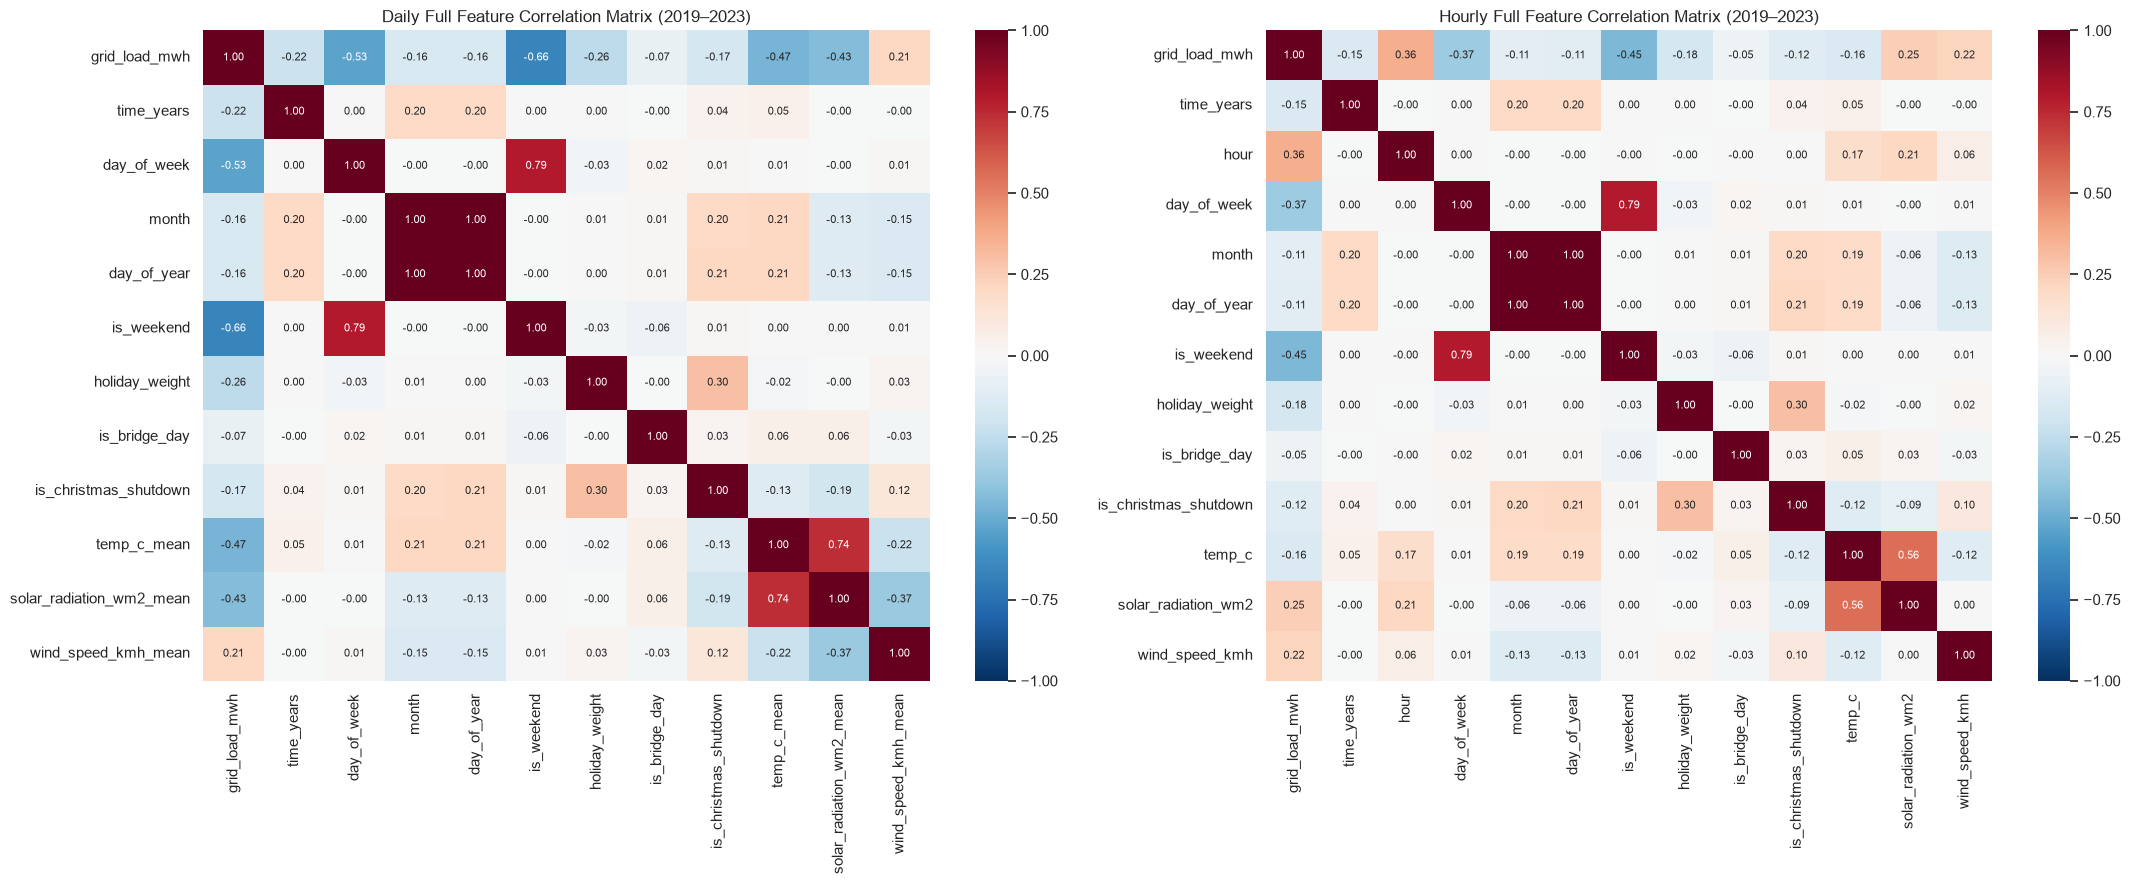

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9))

daily_corr_cols = [TARGET_COL, *DAILY_FULL_YEAR_COLS]
sns.heatmap(
    train_d[daily_corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 8},
    ax=axes[0],
)
axes[0].set_title("Daily Full Feature Correlation Matrix (2019–2023)")

hourly_corr_cols = [TARGET_COL, *HOURLY_FULL_YEAR_COLS]
sns.heatmap(
    train_h[hourly_corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 8},
    ax=axes[1],
)
axes[1].set_title("Hourly Full Feature Correlation Matrix (2019–2023)")

plt.tight_layout()
plt.show()
